# Coursework
# SPCE0038: Machine Learning with Big-Data

---

## Overview

This coursework is provided as a Jupyter notebook, which you will need to complete.  

Throughout the notebook you will need to complete code, analytic exercises (if equations are required please typeset your solutions using latex in the markdown cell provided) and descriptive answers. Much of the grading of the coursework will be performed automatically, so it is critical you name your variables as requested.

Before you turn this coursework in, make sure everything runs as expected. First, **restart the kernel** (in the menubar, select Kernel$\rightarrow$Restart) and then **run all cells** (in the menubar, select Cell$\rightarrow$Run All).

Make sure you fill in any place that says "YOUR ANSWER HERE" or `YOUR CODE HERE` and remove remove the `raise NotImplementedError()` exceptions that are thrown before you have added your answers.

Please also:
- Make sure you use a python environment using the `requirements.txt` files provided by the course.
- Make sure your notebook executes without errors.
- Do not add and remove cells but only provide your answers in the spaces given.
- Do not add or change code in the cells other than the ones marked with `# YOUR CODE HERE`.
- Do not overwrite or rename any existing variables.
- Do not install code or packages in the notebooks.
- Do not import any libraries other than modules from `sklearn`.
- Always label your plots.
- Answer the questions concisely and show your work/derivations/reasoning.

**Please rename the notebook filename to include your candidate number in the filename.  And please also add your candidate number below:**

In [1]:
CANDIDATE_NUMBER = 25225451

You will be able to run some basic tests in the notebook to check the basic operation of your code is as expected.  Although do not assume your responses are complete or fully correct just because the basic tests pass.

Once you have renamed the notebook file and completed the exercises, please upload the notebook to Moodle.


---

## AstroML

The data used is this coursework is obtained using [AstroML](http://www.astroml.org), a python package for machine learning for astronomy.  Although we take data from AstroML, this coursework is not based on standard AstroML examples.  So you will *not* find the solutions in AstroML examples!

## SDSS

The data obtained through AstroML was observed by the [Sloan Digital Sky Survey](https://www.sdss.org/) (SDSS), which began observations in 2000.  SDSS data have lead to many scientific advances and the experiment is widely seen as one of the most successful surveys in the history of astronomy.

---

## Dependencies

- Standard course dependencies (e.g. numpy, scikit-learn, etc.)
- [AstoML](http://www.astroml.org)
- [AstroPy](http://www.astropy.org/)

---

In [2]:
import numpy as np
from matplotlib import pyplot as plt
import pandas as pd

In [3]:
def check_var_defined(var):
    try:
        exec(var)
    except NameError:
        raise NameError(var + " not defined.")
    else:
        print(var + " defined.")

## Part 1: Regression

In these exercises we will consider the regression problem of the astonomical distance modulus vs redshift relationship.

In astronomy, the [distance modulus](https://en.wikipedia.org/wiki/Distance_modulus) specifies the difference between the apparent and absolute magnitudes of an astronomnical object.  It provides a way of expressing astrophysical distances. 

Astronomical [redshift](https://en.wikipedia.org/wiki/Redshift) specifies the shift in wavelength that astronomical objects undergo due to the expansion of the Universe.  Due to Hubble's Law, more distance objects experience a greater redshift.


In [4]:
from astroML.datasets import generate_mu_z

In [5]:
# Load data
m = 150 # number of samples
z_sample, mu_sample, dmu = generate_mu_z(m, random_state=3) # generate distance modulus and redshift data

*Plot the distance modulus ($\mu$) vs redhift ($z$), including error bars.*

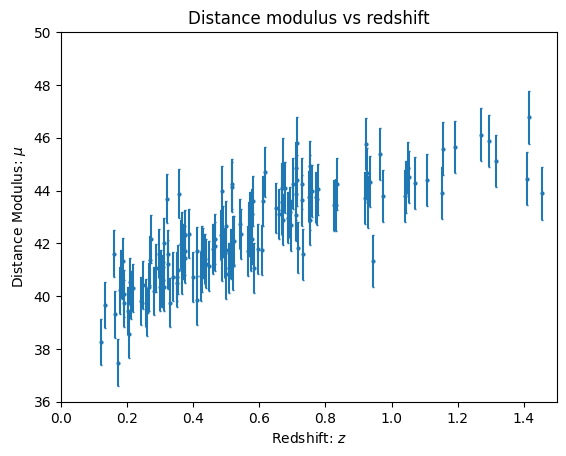

In [6]:
# Plot data
def plot_dist_mod():
    df = pd.DataFrame({'z': z_sample, 'mu': mu_sample})
    plt.errorbar(df['z'], df['mu'], yerr=dmu, fmt='o', markersize=2, capsize=1)
    
    plt.xlabel('Redshift: $z$')
    plt.ylabel('Distance Modulus: $\mu$')
    plt.title('Distance modulus vs redshift')
    plt.ylim(36, 50)
    plt.xlim(0, 1.5)
plot_dist_mod()

Recall the normal equations for linear regression follow by analytically minimising the cost function: 

$$\min_\theta\ C(\theta) = \min_\theta \ (X \theta - y)^{\rm T}(X \theta - y).$$

Show analytically that the solution is given by 

$$ \hat{\theta} = \left( X^{\rm T} X \right)^{-1} X^{\rm T} y. $$

[Matrix calculus identities](https://en.wikipedia.org/wiki/Matrix_calculus) may be useful (note that we use the denominator layout convention).

*Expand the cost function and drop terms that do not depend on $\theta$ (use latex mathematics expressions):*

Minimising the mean square error is equivalent to minimising the cost function:

$$C({\theta}) = \frac{1}{n} ({X}{\theta} - {y})^T ({X}{\theta} - {y})$$

Which, when expanded results in:

$$C(\theta) = \frac{1}{n} (\theta^T {X}^T{X} {\theta} + {y}^T {y} - {y}^T {X}{\theta} - {y} {X}^T{\theta}^T)$$

The last two terms in this expression are both inner products of $n$-dimensional vectors, resulting in two scalars. The transpose of a scalar is itsself, so the last two terms combine and the expression now becomes:

$$C({\theta}) = \frac{1}{n} ( {\theta}^T{X}^T {X} {\theta} + {y}^T {y} - 2{y}^T {X}{\theta})$$


*Calculate the derivative, set it to zero, and solve for $\theta$ (use latex mathematics expressions):*

Differentiating with respect to ${\theta}$ obtains the gradient, which gives us the direction of steepest increase of the cost function at any point, ${\theta}$:

$$\nabla_{\theta} C = \frac{1}{n} ( 2{X}^T {X} {\theta} - 2{X}^T {y}) $$

 $$= \frac{2}{n} ( {X}^T {X} {\theta} - {X}^T {y} )$$

We set this expression to zero since we are interested in where the function is at a minimum,

 $$\frac{2}{n} ( {X}^T {X} {\theta} - {X}^T {y} ) = {0}$$

 The $\frac{2}{n}$ term is a positive scalar that can be dropped, thus the expression becomes:

 $${X}^T {X}{\theta} = {X}^T {y}$$

Which, when solved for ${\theta}$ becomes,

$${\hat{\theta}} = ( {X}^T {X} )^{-1} {X}^T {y}$$


*Solve for $\theta$ by numerically implementing the analytic solution given above.*

In [7]:
def compute_theta_lin_reg(X, y):
    X_b = np.column_stack([np.ones(len(X)), X]) # add bias term (intercept) to features
    theta = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y # normal equation from above
    return theta

compute_theta_lin_reg(z_sample, mu_sample).shape

(2,)

In [8]:
assert compute_theta_lin_reg(z_sample, mu_sample).shape == (2,)
theta = compute_theta_lin_reg(z_sample, mu_sample)
(theta_c, theta_m) = theta
print("Linear regression parameters recovered analytically: intercept={0:.4f}, slope={1:.4f}".format(theta_c, theta_m))

Linear regression parameters recovered analytically: intercept=39.5505, slope=4.9538


In [9]:
check_var_defined('theta_c')
check_var_defined('theta_m')

theta_c defined.
theta_m defined.


*Write a method to make a prediction for a given redshift.*

In [10]:
def predict_lin_reg(theta, x):
    # theta.shape = (2,) with values [39.5505, 4.9538]
    y = theta[0] + theta[1] * x
    return y

*Predict the distance modulus for a range of redshift values between 0.01 and 1.5 and plot the predicted curve overlayed on data (make a new plot; do not revise the plot above).  Call the variable used to store the predictions for your polynomial model `mu_pred_lin`.*

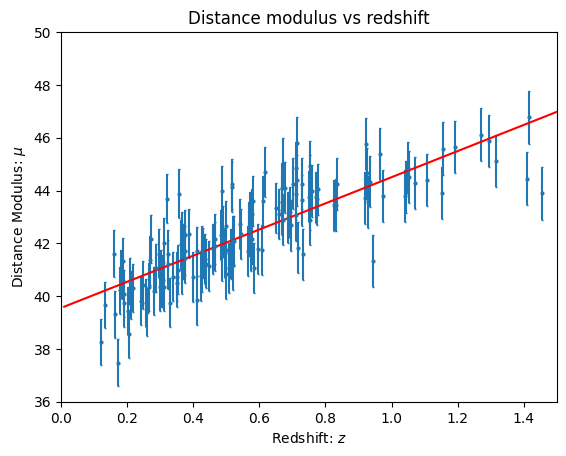

In [11]:
z = np.linspace(0.01, 1.5, 1000)
plot_dist_mod()
mu_pred_lin = predict_lin_reg(theta, z)


plt.plot(z, mu_pred_lin, color='red', label='Linear regression fit')


In [12]:
check_var_defined('mu_pred_lin')
assert mu_pred_lin.shape == (len(z),), "Make sure the shape of your predictions is correct"

mu_pred_lin defined.


*Solve for the parameters $\theta$ using Scikit-Learn.*

In [13]:
from sklearn.linear_model import LinearRegression
lin_reg = LinearRegression()
def compute_theta_lin_reg_sklearn(X, y):
    global lin_reg
    X = X.reshape(-1, 1) # reshape to 2D array (150,) -> (150, 1) 
    lin_reg.fit(X, y)
    return lin_reg.coef_, lin_reg.intercept_

theta_sklearn = compute_theta_lin_reg_sklearn(z_sample, mu_sample)


In [14]:
assert lin_reg.coef_.shape == (1,), "Make sure your features have the right shape, such that we have 1 fitted coefficient"
print("Linear regression parameters recovered by scikit-learn: intercept={0:.4f}, slope={1:.4f}"
      .format(lin_reg.intercept_, lin_reg.coef_[0]))

Linear regression parameters recovered by scikit-learn: intercept=39.5505, slope=4.9538


*Extend your model to include polynomial features up to degree 15 (using Scikit-Learn).  Use variable `lin_reg_poly` for your revised model.*

In [ ]:
degree = 15
bias = False
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split

def compute_poly_features(degree, bias):
    # Return polynomial features of samples and class
    poly_features = PolynomialFeatures(degree=degree, include_bias=bias)
    z_sample_poly = poly_features.fit_transform(z_sample.reshape(-1, 1))    
    return z_sample_poly, poly_features                                     

z_sample_poly, poly_features = compute_poly_features(degree, bias)

lin_reg_poly = LinearRegression()
lin_reg_poly.fit(z_sample_poly, mu_sample) # fit linear regression to polynomial features

LinearRegression()

In [16]:
check_var_defined('lin_reg_poly')

lin_reg_poly defined.


*Plot the data and the predictions of your models considered so far (linear and polynomial regression).  Call the variable used to store the predictions for your polynomial model `mu_pred_poly`.*

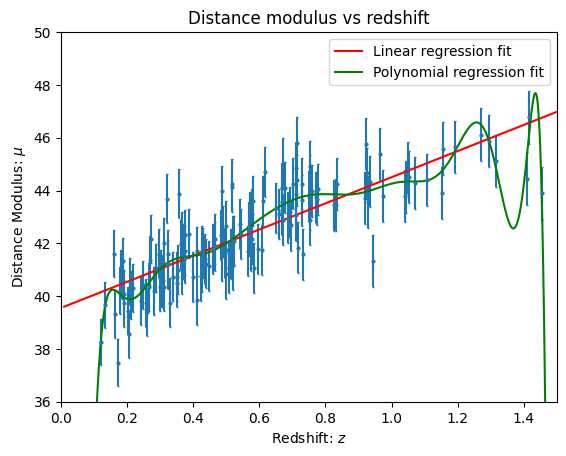

In [17]:
z_poly = poly_features.transform(z.reshape(-1, 1))
mu_pred_poly = lin_reg_poly.predict(z_poly)

# Plotting linear model:
def plot_linear_model():
    plot_dist_mod()
    plt.plot(z, mu_pred_lin, color='red', label='Linear regression fit')
    plt.plot(z, mu_pred_poly, color='green', label='Polynomial regression fit')
    plt.legend()

plot_linear_model()

In [18]:
check_var_defined('mu_pred_poly')
assert mu_pred_poly.shape == (len(z),)


mu_pred_poly defined.


*Comment on the accuracy of your models.*

The linear model seems to generalise much better. Polynomial fit is overfitting the data, as we can see from the plot. The polynomial curve does not capture the overall trend of the data, it is trying to fit noise. Whereas, linear fit seems to be a better representation of the underlying relationship between redshift and distance modulus in this case.

*Think about methods that could be used to improve the performance of your models. Improve your polynomial model and use the improved model to make predictions. Call the variable used to store the polynomial model `ridge_reg_poly`. Call the variable used to store the predictions for your polynomial model `mu_pred_poly_improved`.*

$(x^{14}, x^{15})$ can become extremely large or small depending on the range of $x$ which can make $X^TX$ ill-conditioned. This is why feature scaling or using orthogonal polynomials is often important.

Ridge good when You have more features than observations (p>n).

In [19]:
from sklearn.linear_model import Ridge

z_sample_poly, poly_features = compute_poly_features(degree, bias)
z_poly = poly_features.transform(z.reshape(-1, 1)) # transform z to polynomial features for prediction

ridge_reg_poly = Ridge(alpha=0.1)
ridge_reg_poly.fit(z_sample_poly, mu_sample)
mu_pred_poly_improved = ridge_reg_poly.predict(z_poly)


In [20]:
check_var_defined('ridge_reg_poly')
check_var_defined('mu_pred_poly_improved')
assert mu_pred_poly_improved.shape == (len(z),), "Make sure the shape of your predictions is correct"

ridge_reg_poly defined.
mu_pred_poly_improved defined.


*Plot the predictions made with new model and all previous models considered.*

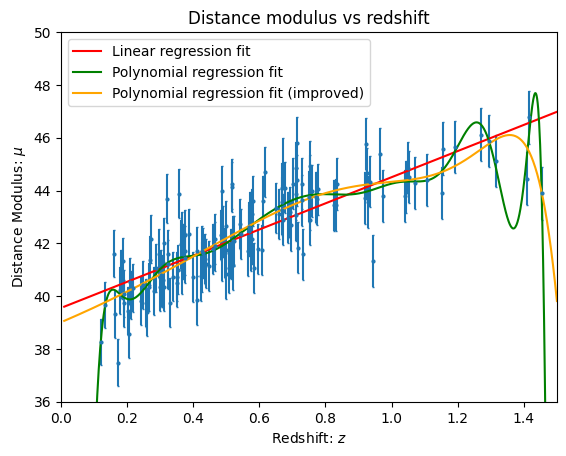

In [21]:
def plot_poly_model():
    plot_dist_mod()
    plt.plot(z, mu_pred_lin, color='red', label='Linear regression fit')
    plt.plot(z, mu_pred_poly, color='green', label='Polynomial regression fit')
    plt.plot(z, mu_pred_poly_improved, color='orange', label='Polynomial regression fit (improved)')
    plt.legend()

plot_poly_model()

*Compute the RMS error between your predictions and the data samples.*

In [22]:
# Define a general function to compute the RMS error
def compute_rms(mu_1, mu_2):
    return np.sqrt(np.mean((mu_1 - mu_2) ** 2))

In [23]:
assert np.isclose(compute_rms(mu_pred_lin, mu_pred_lin), 0.0)

In [24]:
len(mu_pred_poly)

1000

In [25]:
# Compute the RMS error between the data and the predictions for each model.
# Use variables rms_sample_lin, rms_sample_poly and rms_sample_poly_improved.
rms_z_sample_poly = poly_features.transform(z_sample.reshape(-1, 1))

rms_sample_lin = compute_rms(lin_reg.predict(z_sample.reshape(-1, 1)), mu_sample)
rms_sample_poly = compute_rms(lin_reg_poly.predict(z_sample_poly), mu_sample)
rms_sample_poly_improved = compute_rms(ridge_reg_poly.predict(rms_z_sample_poly), mu_sample)



In [26]:
# Print RMS values computed.
print("rms_sample_lin = {0:.4f}".format(rms_sample_lin))
print("rms_sample_poly = {0:.4f}".format(rms_sample_poly))
print("rms_sample_poly_improved = {0:.4f}".format(rms_sample_poly_improved))

rms_sample_lin = 1.0084
rms_sample_poly = 0.8855
rms_sample_poly_improved = 0.9194


In [27]:
check_var_defined('rms_sample_lin')

rms_sample_lin defined.


In [28]:
check_var_defined('rms_sample_poly')

rms_sample_poly defined.


In [29]:
check_var_defined('rms_sample_poly_improved')

rms_sample_poly_improved defined.


*Comment on what models you believe are best.*

The polynomial model `rms_sample_poly` has the lowest error on the training data, however this does not necessarily indicate it being a better model, since as previously mentioned, it is overfitting the data and accomodating for the noise in the dataset, not capturing the trend of the data.\
The 'improved' polynomial model has a poorer rms score, `rms_sample_poly_improved`, however graphically it seems to generalise the dataset better, indicating that the Ridge regularisation efforts did not necessarily reduce the error caused by overfitting but it better represented the underlying general trend.\
Although `rms_sample_lin` achieved the poorest rms score, it still captured the trend of the data. Further analysis is required to determine which model is 'best' between `lin_reg` and `ridge_reg_poly`. However, if I was to have to give an answer of which is best, it would be `ridge_reg_poly`.

Using our cosmological concordance model we can predict the theoretical distance modulus vs redshift relationship using our understanding of the physics.

In [30]:
from astroML.cosmology import Cosmology
cosmo = Cosmology()
mu_cosmo = np.array(list(map(cosmo.mu, z)))

        Use astropy.cosmology instead. [warnings]


*Plot the data, predictions made with all regression models, and the values predicted by the cosmological model.*

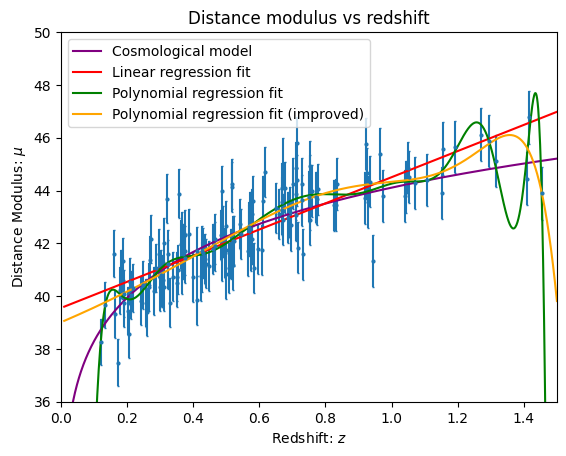

In [31]:
def plot_cosmo_model():
    plot_dist_mod()
    plt.plot(z, mu_cosmo, color='purple', label='Cosmological model')
    plt.plot(z, mu_pred_lin, color='red', label='Linear regression fit')
    plt.plot(z, mu_pred_poly, color='green', label='Polynomial regression fit')
    plt.plot(z, mu_pred_poly_improved, color='orange', label='Polynomial regression fit (improved)')
    plt.legend()

plot_cosmo_model()

*Compute the RMS error between the predictions made by the cosmological model and each of the regression models, over the sample array `z`.*

In [32]:
# Compute the RMS error between the data and the predictions for each model.
# Use variables rms_cosmo_lin, rms_cosmo_poly and rms_cosmo_poly_improved.
rms_cosmo_lin = compute_rms(mu_cosmo, mu_pred_lin)
rms_cosmo_poly = compute_rms(mu_cosmo, mu_pred_poly)
rms_cosmo_poly_improved = compute_rms(mu_cosmo, mu_pred_poly_improved)

In [33]:
# Print RMS values computed.
print("rms_cosmo_lin = {0:.4f}".format(rms_cosmo_lin))
print("rms_cosmo_poly = {0:.4f}".format(rms_cosmo_poly))
print("rms_cosmo_poly_improved = {0:.4f}".format(rms_cosmo_poly_improved))

rms_cosmo_lin = 1.1252
rms_cosmo_poly = 20.6653
rms_cosmo_poly_improved = 1.0413


In [34]:
check_var_defined('rms_cosmo_lin')

rms_cosmo_lin defined.


In [35]:
check_var_defined('rms_cosmo_poly')

rms_cosmo_poly defined.


In [36]:
check_var_defined('rms_cosmo_poly_improved')

rms_cosmo_poly_improved defined.


*Comment on the RMS values computed and the implications for the accuracy of the different regression models considered.*

`rms_cosmo_poly` performed significantly worse than the other two models, with a large rms value. This is likely due to the model largely overfitting the data. \
`rms_cosmo_lin` performs considerably better, but with the `mu_cosmo` model being the theoretical prediction, it is clear there is not a linear relationship.\
`rms_cosmo_poly_improved` achieved the lowest rms error between the cosmological model, as well as capturing the underlying trend in the data that the model also shows. 

---

## Part 2: Classification

In these exercises we will consider classification of [RR Lyrae](https://en.wikipedia.org/wiki/RR_Lyrae_variable) variable stars.  RR Lyrae variables are often used as standard candles to measure astronomical distances since their period of pulsation can be related to their absolute magnitude.

Observations of star magnitudes are made in each [SDSS filter band](http://skyserver.sdss.org/dr2/en/proj/advanced/color/sdssfilters.asp): u, g, r, i, z.

We will consider the space of astronomical "colours" to distinguish RR Lyraes from background stars.  Astronomical colours are simply differences in magnitudes between bands, e.g. u-g, g-r, r-i, i-z.  You can find further background [here](https://en.wikipedia.org/wiki/Color%E2%80%93color_diagram).

First, download the data.  (This may take some time on first execution.  Subsequently executions will read from cached data on your system.)

In [37]:
# Load data
from astroML.datasets import fetch_rrlyrae_combined
X, y = fetch_rrlyrae_combined()

You can learn more about the format of the returned data [here](http://www.astroml.org/modules/generated/astroML.datasets.fetch_rrlyrae_combined.html).  In particular, note that the columns of `X` are u-g, g-r, r-i, i-z.

*Construct a Pandas DataFrame for the `X` data and a Series for the `y` data.  Call your Pandas objects `X_pd` and `y_pd` respectively.*

Be sure to give your colums the correct colour name, e.g. 'u-g'.

In [38]:
import pandas as pd
cols=['u-g', 'g-r', 'r-i', 'i-z']
X_pd = pd.DataFrame(X, columns=cols)

In [39]:
check_var_defined('X_pd')
print(X_pd)

X_pd defined.
            u-g       g-r       r-i       i-z
0      1.250999  0.394000  0.137000  0.061999
1      1.048000  0.339001  0.151999  0.023001
2      1.008001  0.341999  0.129000  0.203001
3      0.965000  0.392000  0.149000  0.150000
4      1.040001  0.333000  0.125999  0.101999
...         ...       ...       ...       ...
93136  0.962999  0.059000 -0.025999 -0.025000
93137  1.059999  0.185001  0.050999 -0.023998
93138  1.044001  0.212000  0.035000  0.002001
93139  1.064999  0.172001  0.042000  0.003000
93140  1.125999  0.065001 -0.017000 -0.057999

[93141 rows x 4 columns]


In [40]:
y_pd = pd.Series(y, name='class')

In [41]:
check_var_defined('y_pd')
print(y_pd)

y_pd defined.
0        0.0
1        0.0
2        0.0
3        0.0
4        0.0
        ... 
93136    1.0
93137    1.0
93138    1.0
93139    1.0
93140    1.0
Name: class, Length: 93141, dtype: float64


*Combine your data and targets into a single Pandas DataFrame, labelling the target column 'target'.  Call the resulting Pandas DataFrame `X_pd_all`.*

In [42]:
# Combining data and targets into a single DataFrame
X_pd_all = pd.concat([X_pd, y_pd], axis=1)
# labelling the target column 'target'
X_pd_all = X_pd_all.rename(columns={y_pd.name: 'target'})
X_pd_all.head()

,u-g,g-r,r-i,i-z,target
0,1.250999,0.394000,0.137000,0.061999,0.0
1,1.048000,0.339001,0.151999,0.023001,0.0
2,1.008001,0.341999,0.129000,0.203001,0.0
3,0.965000,0.392000,0.149000,0.150000,0.0
4,1.040001,0.333000,0.125999,0.101999,0.0


In [43]:
check_var_defined('X_pd_all')
print(X_pd_all)

X_pd_all defined.
            u-g       g-r       r-i       i-z  target
0      1.250999  0.394000  0.137000  0.061999     0.0
1      1.048000  0.339001  0.151999  0.023001     0.0
2      1.008001  0.341999  0.129000  0.203001     0.0
3      0.965000  0.392000  0.149000  0.150000     0.0
4      1.040001  0.333000  0.125999  0.101999     0.0
...         ...       ...       ...       ...     ...
93136  0.962999  0.059000 -0.025999 -0.025000     1.0
93137  1.059999  0.185001  0.050999 -0.023998     1.0
93138  1.044001  0.212000  0.035000  0.002001     1.0
93139  1.064999  0.172001  0.042000  0.003000     1.0
93140  1.125999  0.065001 -0.017000 -0.057999     1.0

[93141 rows x 5 columns]


*Add a 'target description' column to your existing `X_pd_all` DataFrame, with fields 'Background' and 'RR Lyrae' to specify the target type.*

In [44]:
X_pd_all['Target Description'] = X_pd_all['target'].map({0: 'Background', 1: 'RR Lyrae'})

In [45]:
print(X_pd_all)

            u-g       g-r       r-i       i-z  target Target Description
0      1.250999  0.394000  0.137000  0.061999     0.0         Background
1      1.048000  0.339001  0.151999  0.023001     0.0         Background
2      1.008001  0.341999  0.129000  0.203001     0.0         Background
3      0.965000  0.392000  0.149000  0.150000     0.0         Background
4      1.040001  0.333000  0.125999  0.101999     0.0         Background
...         ...       ...       ...       ...     ...                ...
93136  0.962999  0.059000 -0.025999 -0.025000     1.0           RR Lyrae
93137  1.059999  0.185001  0.050999 -0.023998     1.0           RR Lyrae
93138  1.044001  0.212000  0.035000  0.002001     1.0           RR Lyrae
93139  1.064999  0.172001  0.042000  0.003000     1.0           RR Lyrae
93140  1.125999  0.065001 -0.017000 -0.057999     1.0           RR Lyrae

[93141 rows x 6 columns]


*How many RR Lyrae variable stars are there in the dataset (i.e compute `n_rrlyrae`)?*

In [46]:
n_rrlyrae = X_pd_all['Target Description'].value_counts()
print(n_rrlyrae)

Target Description
Background    92658
RR Lyrae        483
Name: count, dtype: int64


In [47]:
check_var_defined('n_rrlyrae')
print("n_rrlyrae = {0}".format(n_rrlyrae))

n_rrlyrae defined.
n_rrlyrae = Target Description
Background    92658
RR Lyrae        483
Name: count, dtype: int64


*How many background stars are there in the dataset (i.e. compute `n_background`)?*

In [48]:
n_background =X_pd_all['Target Description'].value_counts()[0]

In [49]:
check_var_defined('n_background')
print("n_background = {0}".format(n_background))

n_background defined.
n_background = 92658


*Plot scatter plot pairs for all colour combinations using `seaborn`.  Colour the points by target type. Make sure the distribution plots are normalised to have an area of 1 under the curve for each of the classes.*

In [50]:
%matplotlib inline
import seaborn as sns; sns.set()

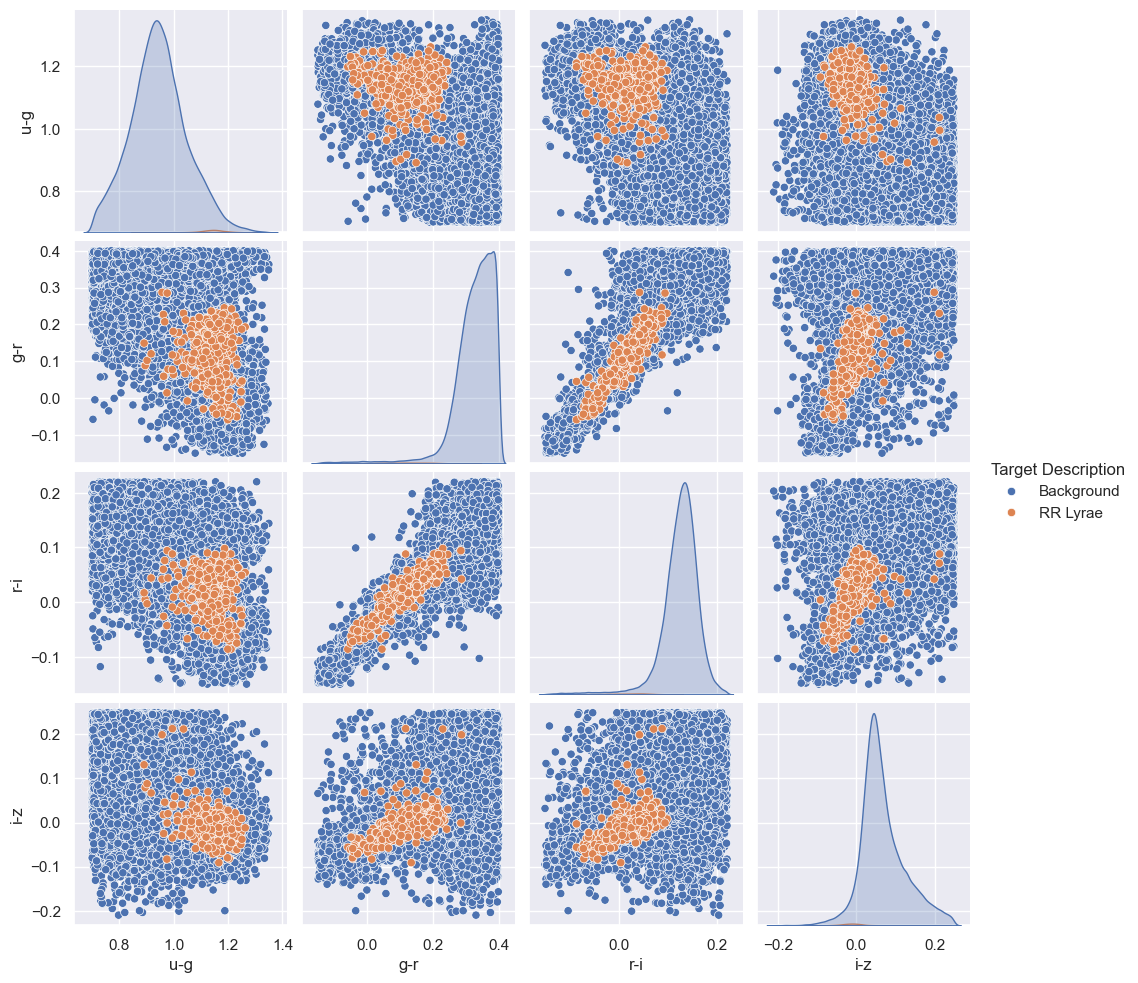

In [51]:
sns.pairplot(X_pd_all, hue='Target Description', vars=cols, diag_kind='kde')

Let's separate the data into training and test sets, keeping 25% of the data for testing.  

In [52]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=1)

First let's consider 1D classification for the zeroth colour, i.e. $u-g$. 

In [53]:
ind = 0
col=cols[ind]
col

'u-g'

In [54]:
X_train_1d = X_train[:, ind]
X_train_1d = X_train_1d.reshape(-1,1)
X_test_1d = X_test[:, ind]
X_test_1d = X_test_1d.reshape(-1,1)

To get some further intuition about the 1D classiciation problem consider a 1D plot of
class against colour.

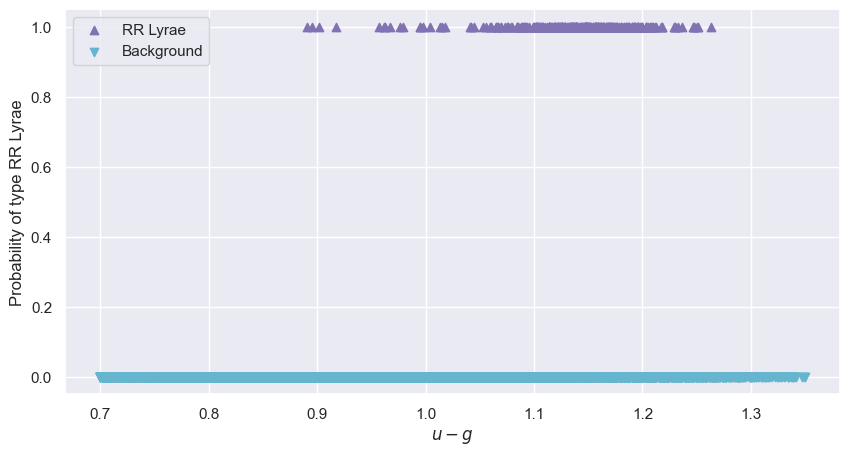

In [55]:
def plot_scatter():
    plt.figure(figsize=(10,5))
    plt.scatter(X_train_1d[y_train==1], y_train[y_train==1], c='m', marker='^', label='RR Lyrae')
    plt.scatter(X_train_1d[y_train==0], y_train[y_train==0], c='c', marker='v', label='Background')
    plt.xlabel('$' + col + '$')
    plt.ylabel('Probability of type RR Lyrae')
plot_scatter()    
plt.legend()

*Given the plot shown above, comment on how well you expect logistic regression to perform.*

The Background class ($y=0$) dominates significantly. There is a large dense band of Background points along $y = 0 $ across the $u - g$ range. \
RR Lyrae appear to span between $u - g \approx 0.9-1.25 $ with a more dense region existing between $u - g \approx 1.5-1.2 $. \
However, due to the huge class inbalance (`n_background = 92658`, `n_rrlyrae = 483`), logistic regression will perform poorly in detecting RR Lyrae. It will achieve high accuracy since it will likely predict Background for everything, but it will not capture RR Lyrae instances.

*Where would you guess the decision bounary should lie?  Set the variable `decision_boundary_guess` to your guess.*

In [56]:
decision_boundary_guess = 1.125

In [57]:
check_var_defined('decision_boundary_guess')
print("decision_boundary_guess = {0:.4f}".format(decision_boundary_guess))

decision_boundary_guess defined.
decision_boundary_guess = 1.1250


Use Scikit-Learn to perform logistic regression to classify the two classes for this 1D problem.

First, set the inverse regularation strength `C` such that regularisation is effecitvely not performed.

In [58]:
C = 1e10

*Second, fit the model using Scikit-Learn. Use the variable `clf` for your classification model.*

In [59]:
from sklearn.linear_model import LogisticRegression
clf = LogisticRegression(C=C, random_state=42)
clf.fit(X_train_1d, y_train)

LogisticRegression(C=10000000000.0, random_state=42)

In [60]:
check_var_defined('clf')

clf defined.


*Compute the decision boundary of the logistic regression model fitted by Scikit-Learn.  User variable `decision_boundary_sklearn` for your result.*

(Ensure your result is a scalar and not an array of length 1.)

Our decision boundary is defined by:

$$\theta_0 + \theta_1 x = 0$$

Solving for x:

$$x = -\frac{\theta_0}{\theta_1}$$


In [61]:
decision_boundary_sklearn = float(-clf.intercept_ / clf.coef_)

In [62]:
assert not hasattr(decision_boundary_sklearn, "__len__")
print("decision_boundary_sklearn = {0:.4f}".format(decision_boundary_sklearn))

decision_boundary_sklearn = 1.3719


*Evaluate the probabilities predicted by your logistic regression model over the domain specified by the variable `X_1d_new`. Use variable `y_1d_proba` for your computed probabilities.*

In [63]:
X_1d_new = np.linspace(0.7, 1.4, 1000).reshape(-1, 1)
y_1d_proba = clf.predict_proba(X_1d_new)[:,1].reshape(-1, 1) # probability of class 1 (RR Lyrae) for each value in X_1d_new


In [64]:
check_var_defined('y_1d_proba')

y_1d_proba defined.


*Plot the probability of a star being of type RR Lyrae against the colour variable considered.  Also plot the probability of being a Background star.  Overlay these plots on the scatter plot of class types.  Also plot the decision boundary that you guessed previously and the one computed by Scikit-Learn.*

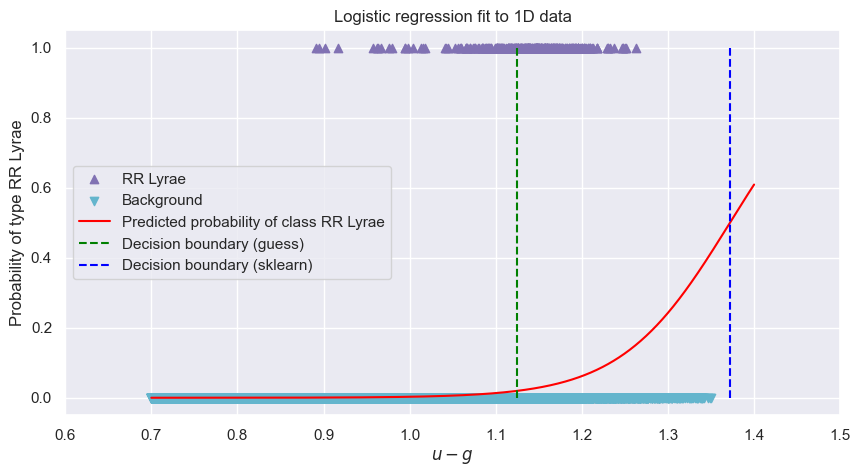

In [65]:
plot_scatter()
plt.xlim(0.6, 1.5)
plt.title('Logistic regression fit to 1D data')
plt.plot(X_1d_new, y_1d_proba, color='red', label='Predicted probability of class RR Lyrae')
plt.plot([decision_boundary_guess, decision_boundary_guess], [0, 1], color='green', linestyle='--', label='Decision boundary (guess)')
plt.plot([decision_boundary_sklearn, decision_boundary_sklearn], [0, 1], color='blue', linestyle='--', label='Decision boundary (sklearn)')
plt.legend()

*From inspection of your plot, how would all objects in the training set be classified?*

All objects would be classified as Background. This is due to the class inbalance, with Background starts outnumbering RR Lyrae.

*Use your logistic regression model fitted by Scikit-Learn to predict the class of all objects in the test set. Use variable `y_test_1d_pred` to specify your answer.*

In [66]:
y_test_1d_pred = clf.predict(X_test_1d)

In [67]:
check_var_defined('y_test_1d_pred')

y_test_1d_pred defined.


*How many objects are classified as of type RR Lyrae?  Use variable `n_rrlyrae_pred` to specify your answer.*

In [68]:
n_rrlyrae_pred = np.sum(y_test_1d_pred)

In [69]:
check_var_defined('n_rrlyrae_pred')
assert n_rrlyrae_pred % 1 == 0 # check integer
print("n_rrlyrae_pred = {0}".format(n_rrlyrae_pred))

n_rrlyrae_pred defined.
n_rrlyrae_pred = 0.0


*How many objects are classified as of type Background?  Use variable `n_background_pred` to specify your answer.*

In [70]:
n_background_pred = len(y_test_1d_pred) - n_rrlyrae_pred

In [71]:
check_var_defined('n_background_pred')
assert n_background_pred % 1 == 0 # check integer
print("n_background_pred = {0}".format(n_background_pred))

n_background_pred defined.
n_background_pred = 23286.0


Let's check the Scikit-Learn result by solving the logistic regression problem (without regularisation) manually.

Recall that the cost function for logistic regression is given by
$$
C(\theta) = -\frac{1}{m} \sum_{i=1}^m 
\left [ 
y^{(i)} \log(\hat{p}^{(i)})
+
(1 - y^{(i)}) \log(1 - \hat{p}^{(i)})
\right],
$$


where

$$\hat{p} = \sigma(\theta^\text{T} x) = \frac{1}{1+\exp{(-\theta^\text{T} x)}}. $$

Show analytically that the derivative of the cost function is given by

$$\begin{eqnarray}
\frac{\partial C}{\partial \theta} 
&=& 
\frac{1}{m} \sum_{i=1}^m 
\left[ \sigma\left(\theta^{\rm T} x^{(i)} \right) - y^{(i)} \right]
x^{(i)}\\
&=&
\frac{1}{m} 
X^{\rm T}
\left[ \sigma\left(X \theta \right) - y \right]
\end{eqnarray}$$

(use latex mathematics expressions).

*First, simplify the cost function terms $\log(\hat{p})$ and $\log(1-\hat{p})$ to express in terms linear in $\log\left({1+{\rm e}^{-\theta^{\rm T}x}}\right)$.*

(You may drop $i$ superscripts for notational brevity.)

$\log(\hat{p})$:
$$
\log(\hat{p}) = \log(\frac{1}{1+\exp{(-\theta^{T} x)}})
= - \log(1 + \exp{(- \theta^{T} x)})$$ 

$\log(1-\hat{p})$:
$$
1 - \hat{p} = 1 - \frac{1}{1+\exp{(-\theta^{T} x)}} = \frac{\exp{(-\theta^{T} x)}}{1 + \exp{(- \theta^{T} x})}$$
$$
\log(1 - \hat{p}) = \log(\exp{(- \theta^{T} x})) - \log(1 + \exp{(- \theta^{T} x})) = - \theta^{T} x - \log(\exp{(- \theta^{T} x}))
$$

*Next, substitute these terms into the cost function and simplify to also express the cost function in terms linear in $\log\left({1+{\rm e}^{-\theta^{\rm T}x}}\right)$.*

Substituting into the cost function:


$$
C(\theta) = -\frac{1}{m} \sum_{i=1}^m 
\left [ 
y \Big(- \log \big(1 + \exp{(- \theta^{T} x)} \big)) \Big)
+
(1 - y) \Bigg(- \theta^{T} x - \log \Big(\exp{(- \theta^{T} x}) \Big) \Bigg)
\right],
$$

Expanding:

$$
C(\theta) = -\frac{1}{m} \sum_{i=1}^m 
\left [ 
y \log(1+ \exp{(- \theta^{T} x)}) - \theta^{T} x - \log(1 + \exp{(- \theta^{T}x) }) + y \theta^{T} x + y \log(1 +\exp{(- \theta^{T} x)}) \right]
$$

$\log$ terms multiplied by $y$ cancel, leaving:

$$
C(\theta) = \frac{1}{m} \sum_{i=1}^m 
\left [ \theta^{T}x - y \theta^Tx + \log(1+ \exp{(- \theta^{T}x) }) \right]
$$

*Now compute the derivative of the cost function with respect to variable $\theta_j$, i.e. compute $\partial C / \partial \theta_j$.*

$$
\frac{\partial C}{\partial \theta} = \frac{1}{m} \sum_{i=1}^m 
\left [ x - yx - (1 - \sigma(\theta^T x)) x \right] 
$$
$$
= \frac{1}{m} \sum_{i=1}^m 
\left [ 1 - y - 1 +\sigma(\theta^T x)\right] x
$$
$$
= \frac{1}{m} \sum_{i=1}^m 
\left [ \sigma(\theta^T x) - y \right] x
$$

*Combine terms for all $\theta_j$ to give the overall derivative with respect to $\theta$, i.e. $\partial C / \partial \theta$.*


$$
\frac{\partial C}{\partial \theta} = \frac{1}{m} X^T 
\left [ \sigma(X \theta^T) - y \right] 
$$

Using the analytically expression for the derivative of the cost function, we will solve the logistic regression problem by implementing a gradient descent algorithm.

*First, define the sigmoid function.*

In [72]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

In [73]:
assert np.isclose(sigmoid(0), 0.5)

*Next, extend the training data to account for a bias term in your model. Use variable `X_train_1d_b` to specify your result.*

In [74]:
# Prepending column of ones to X_train_1d for bias term 
X_train_1d_b = np.column_stack([np.ones(len(X_train_1d)), X_train_1d]) 

In [75]:
check_var_defined('X_train_1d_b')

X_train_1d_b defined.


*Implement batch gradient descent to fit the parameters of your logistic regression model.  Consider `n_iterations = 4000` iterations and a learning rate of `alpha = 100.0`. Consider a starting point of $\theta_0 = (1, 1)$, i.e. `theta = np.array([[1], [1]])`. Use variable `theta` to specify your estimated parameters.*

*(Make sure your implementation is reasonably efficient. If it takes longer than 2 minutes to execute when running on our server it may not complete and you will not be awarded grades. The solution answer runs in under 10 seconds.)*

In [76]:
n_iterations = 4000
alpha = 100.0
theta = np.array([[1.0], [1.0]])

for iteration in range(n_iterations):
    y_hat = sigmoid(X_train_1d_b @ theta)

    gradient = X_train_1d_b.T @ (y_hat - y_train.reshape(-1, 1)) / len(y_train)
    theta -= (alpha * gradient)



In [77]:
check_var_defined('theta')
print("theta[0] = {0:.4f}".format(theta[0][0]))
print("theta[1] = {0:.4f}".format(theta[1][0]))

theta defined.
theta[0] = -21.7012
theta[1] = 15.8177


*Compute the difference between the logistic regression model intercept computed by Scikit-Learn and manually.  Use variable `intercept_diff` for your result.*

In [78]:
intercept_diff = theta[0][0] - clf.intercept_[0]

In [79]:
check_var_defined('intercept_diff')
print("intercept_diff = {0:.4E}".format(intercept_diff))

intercept_diff defined.
intercept_diff = 1.0314E-03


*Compute the difference between the logistic regression model* slope *(i.e. coefficient) computed by Scikit-Learn and manually.  Use variable `coeff_diff` for your result.*

In [80]:
coeff_diff = theta[1][0] - clf.coef_[0][0]

In [81]:
check_var_defined('coeff_diff')
print("coeff_diff = {0:.4E}".format(coeff_diff))

coeff_diff defined.
coeff_diff = -9.0958E-04


You should find that the solution from your gradient descent algorithm is close (although not identical) to that recovered by Scikit-Learn. 

Both fitted logistic regression models, however, are not effective. The reason for this is because of class imbalance.  *Describe the class imbalance problem in your own words and how it manifests itself in the classification problem at hand.*

The class inbalance problem can be described by the logistic regression results observed above. There is a significantly larger number of Background star instances, `n_background`, in the dataset than there is for the RR Lyrae, `n_rrlyrae`. The logistic regression model minimises the cost function, this can be achieved by predicting Background for all instances with little cost sacrificed by not correctly predicting RR Lyrae.

The class imbalance problem can be addressed by weighting the training data in a manner that is inversely proportional to their frequency.

*Repeat the fitting of your linear regression model but this time perform class weighting.  Use variable `clf_balanced` for your new model.*

See the `class_weight` argument of the Scikit-Learn [Logistic Regression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html) classifier for further details on how to perform class weighting.

In [82]:
from sklearn.linear_model import LogisticRegression
clf_balanced = LogisticRegression(C=C, random_state=42, class_weight='balanced')
clf_balanced.fit(X_train_1d, y_train)

LogisticRegression(C=10000000000.0, class_weight='balanced', random_state=42)

In [83]:
check_var_defined('clf_balanced')

clf_balanced defined.


*Compute the decision boundary of the logistic regression model fitted by Scikit-Learn when weighting classes.* 

(Ensure your result is a scalar and not an array of length 1.)

In [84]:
decision_boundary_sklearn_balanced = float(-clf_balanced.intercept_ / clf_balanced.coef_)

In [85]:
check_var_defined('decision_boundary_sklearn_balanced')
assert not hasattr(decision_boundary_sklearn_balanced, "__len__")
print("decision_boundary_sklearn_balanced = {0:.4f}".format(decision_boundary_sklearn_balanced))

decision_boundary_sklearn_balanced defined.
decision_boundary_sklearn_balanced = 1.0597


*Evaluate the probabilities prediced by your new logistic regression model over the domain specified by the variable `X_1d_new`. Use variable `y_1d_proba_balanced` for your computed probabilities.*

In [86]:
y_1d_proba_balanced = clf_balanced.predict_proba(X_1d_new)[:,1].reshape(-1, 1)

In [87]:
check_var_defined('y_1d_proba_balanced')

y_1d_proba_balanced defined.


*For your new balanced model, plot the probability of a star being of type RR Lyrae against the colour variable considered.  Also plot the probability of being a Background star.  Overlay these plots on the scatter plot of class types.  Also plot the decision boundary that you guessed previously, the one computed by Scikit-Learn initially, and the one computed by Scikit-Learn for your new balanced model.*

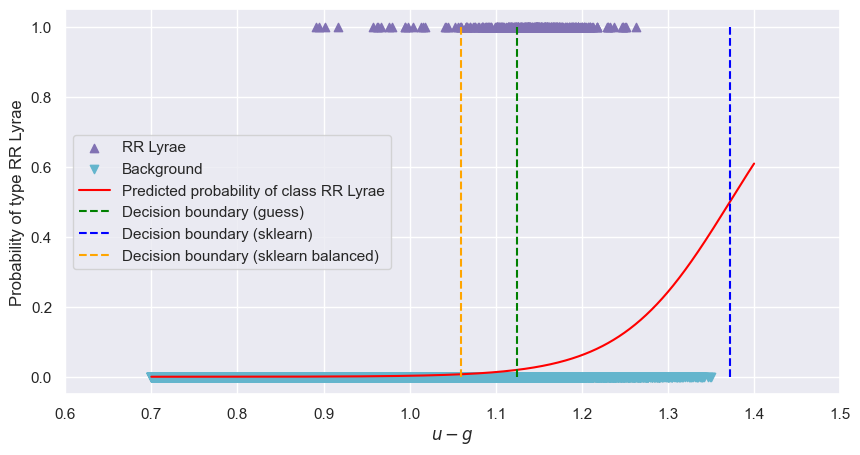

In [88]:
plot_scatter()
plt.xlim(0.6, 1.5)
plt.plot(X_1d_new, y_1d_proba, color='red', label='Predicted probability of class RR Lyrae')
plt.plot([decision_boundary_guess, decision_boundary_guess], [0, 1], color='green', linestyle='--', label='Decision boundary (guess)')
plt.plot([decision_boundary_sklearn, decision_boundary_sklearn], [0, 1], color='blue', linestyle='--', label='Decision boundary (sklearn)')
plt.plot([decision_boundary_sklearn_balanced, decision_boundary_sklearn_balanced], [0, 1], color='orange', linestyle='--', label='Decision boundary (sklearn balanced)')
plt.legend()

*Comment on the decision boundary of the balanced model compared to the unbalanced models fitted previously.*

The descision boundary of the balanced model is significantly lower than the unbalanced decision boundary, as well as being lower than my initial prediction. The unbalanced model is dominated by the unproportionate number of Background stars compared to RR Lyrae stars in the dataset. By addressing the class inbalance problem through class weighting, the model decision boundary shifts left, allowing it to more likely predict RR Lyrae stars.

Now that we've built up good intuition surrounding the subtleties of the classification problem at hand in 1D, let's consider the 2D problem (we will keep to 2D for plotting convenience).

For the 2D case we consider the following colours.

In [89]:
ind = 1
cols[:ind+1]

['u-g', 'g-r']

Consider the following training and test data for the 2D problem.

In [90]:
X_train_2d = X_train[:, :ind+1]
X_train_2d = X_train_2d.reshape(-1,ind+1)
X_test_2d = X_test[:, :ind+1]
X_test_2d = X_test_2d.reshape(-1,ind+1)

*Train a logistic regression model for this 2D problem.  Use variable `clf_2d_logistic` for your classifier.*

In [91]:
clf_2d_logistic = LogisticRegression(C=C, random_state=42)
clf_2d_logistic.fit(X_train_2d, y_train)

LogisticRegression(C=10000000000.0, random_state=42)

In [92]:
check_var_defined('clf_2d_logistic')

clf_2d_logistic defined.


*Compute the precision and recall of your 2D logistic regression model. Use variables `precision_logistic` and `recall_logistic` for your results.*

In [93]:
precision_logistic = clf_2d_logistic.score(X_test_2d, y_test)
recall_logistic = clf_2d_logistic.score(X_test_2d[y_test==1], y_test[y_test==1])

In [94]:
check_var_defined('precision_logistic')
print("precision_logistic = {0:.6f}".format(precision_logistic))

precision_logistic defined.
precision_logistic = 0.994203


In [95]:
check_var_defined('recall_logistic')
print("recall_logistic = {0:.6f}".format(recall_logistic))

recall_logistic defined.
recall_logistic = 0.000000


Consider the following meshgrid defining the u-g and g-r colour domain of interest.

In [96]:
xlim = (0.7, 1.45)  # u-g
ylim = (-0.15, 0.4) # g-r
xx, yy = np.meshgrid(np.linspace(xlim[0], xlim[1], 100),
                     np.linspace(ylim[0], ylim[1], 100))

*Over the domain specified above plot the predicted classification probability.  Overlay on your plot the data instances, highlighting whether a RR Lyrae or background star, and the decision boundary.*

(-0.15, 0.4)

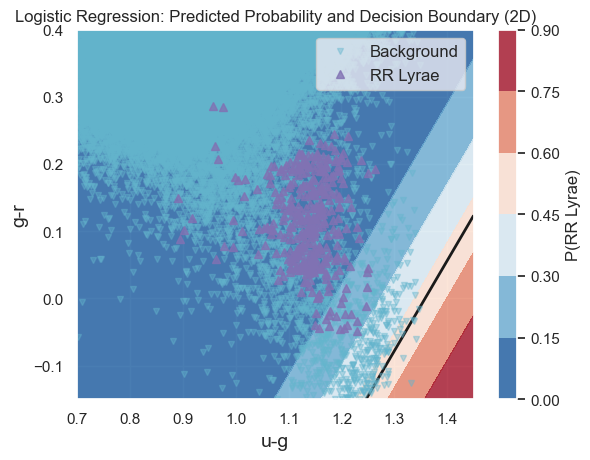

In [97]:
X_new_2d = np.c_[xx.ravel(), yy.ravel()]
y_proba_2d = clf_2d_logistic.predict_proba(X_new_2d)
zz = y_proba_2d[:, 1].reshape(xx.shape)

plt.figure()
plt.contourf(xx, yy, zz, cmap=plt.cm.RdBu_r, alpha=0.8)
plt.colorbar(label='P(RR Lyrae)')

plt.contour(xx, yy, zz, levels=[0.5], colors='k', linewidths=2)
plt.plot(X_train_2d[y_train==0, 0], X_train_2d[y_train==0, 1],
         'cv', alpha=0.4, markersize=4, label='Background')
plt.plot(X_train_2d[y_train==1, 0], X_train_2d[y_train==1, 1],
         'm^', alpha=0.8, markersize=6, label='RR Lyrae')

plt.xlabel('u-g', fontsize=14)
plt.ylabel('g-r', fontsize=14)
plt.legend(loc='upper right', fontsize=12)
plt.title('Logistic Regression: Predicted Probability and Decision Boundary (2D)')
plt.xlim(xlim)
plt.ylim(ylim)



*Now train an SVM classifier that can support a non-linear decision boundary on the same problem. Use the variable `clf_2d_svm` for your model.*

In [102]:
from sklearn.svm import SVC

clf_2d_svm = SVC(kernel='rbf', class_weight='balanced')
clf_2d_svm.fit(X_train_2d, y_train)

SVC(class_weight='balanced')

In [103]:
check_var_defined('clf_2d_svm')

clf_2d_svm defined.


*Replicate for the SVM your plot above for the 2D logistic regression model.  Over the domain specified above plot the decision function score.  Overlay on your plot the data instances, highlighting whether a RR Lyrae or background star, and the decision boundary.*

(-0.15, 0.4)

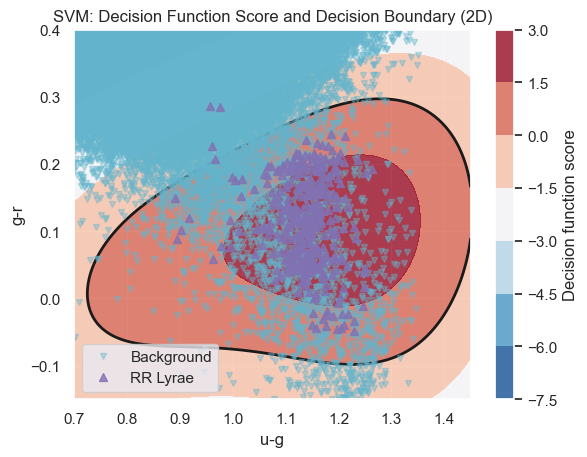

In [104]:
Z_svm = clf_2d_svm.decision_function(X_new_2d).reshape(xx.shape)

plt.figure()
plt.contourf(xx, yy, Z_svm, cmap=plt.cm.RdBu_r, alpha=0.8)
plt.colorbar(label='Decision function score')

plt.contour(xx, yy, Z_svm, levels=[0], colors='k', linewidths=2)
plt.plot(X_train_2d[y_train==0, 0], X_train_2d[y_train==0, 1],
         'cv', alpha=0.4, markersize=4, label='Background')
plt.plot(X_train_2d[y_train==1, 0], X_train_2d[y_train==1, 1],
         'm^', alpha=0.8, markersize=6, label='RR Lyrae')

plt.xlabel('u-g')
plt.ylabel('g-r')
plt.legend()
plt.title('SVM: Decision Function Score and Decision Boundary (2D)')
plt.xlim(xlim)
plt.ylim(ylim)


*Compute the precision and recall of your 2D SVM model. Use variables `precision_svm` and `recall_svm` for your results.*

In [105]:
precision_svm = clf_2d_svm.score(X_test_2d, y_test)
recall_svm = clf_2d_svm.score(X_test_2d[y_test==1], y_test[y_test==1])

In [106]:
check_var_defined('precision_svm')
print("precision_svm = {0:.6f}".format(precision_svm))

precision_svm defined.
precision_svm = 0.964184


In [107]:
check_var_defined('recall_svm')
print("recall_svm = {0:.6f}".format(recall_svm))

recall_svm defined.
recall_svm = 1.000000


*Comment on the difference in decision boundary between your logistic regression and SVM models and how this impacts the effectiveness of the models.*

The logistic regression decision boundary is a straight line, only separating classes linearly. Whereas, the SVM with an RBF kernel produced a curved boundary that encloses the concentration of RR Lyrae stars.\
The recall for the logistic regression model equalled zero since the class imbalance meant it missed all RR Lyrae stars, whereas the SVM model with a balanced class weighting and a non-linear kernel significantly increased the recall -- this increase came at the cost of some accuracy.